# Fruit flies and microplastics: DAM monitor analysis, October 17-22

In [1]:
import re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
import statsmodels.formula.api as smf
import statsmodels.api as sm

In [2]:
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 40)

DATA_FILE = "Monitor1.txt"              
OUTDIR = Path("october 2nd results") 
FIGDIR = OUTDIR / "figures"
FIGDIR.mkdir(parents=True, exist_ok=True)

# analysis settings
ACTIVITY = "MT"          # MT = number of beam-to-beam movements per minute
SLEEP_MIN = 5            # sleep = at least 5 consecutive minutes with no movement
BIN_MIN = 30             # profile bin width (minutes)
DAY_HOURS = 12           # 12 h light, 12 h dark
LIGHTS_ON_CLOCK = None   # e.g. "10:15" to force; None = estimate from the light sensor
DEAD_HOURS = 6           # no movement in the last 6 h of a run -> flag as possibly dead
MIN_VALID_FRAC = 0.80    # tubes with less valid data are excluded
CONTROL_GROUPS = ["Control1", "Control2"]   # pooled into one "Control" for comparisons

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11})
print("Output folder:", OUTDIR.resolve())

Output folder: C:\Users\dell\OneDrive - Texas Tech University\Yim Lab\oct17-22\october 2nd results


In [4]:
WINDOWS = {
    "W1": dict(start="2026-10-17 13:50", end="2026-10-18 13:50", exclude={}, labels=[
        "IGMedOrRF","IGHiOrRF","IGLoYWM","IGLoOrRM","CtrlOrRF","CtrlYWM","IGLoYWF","TGLoOrRM",
        "IGMedYWF","CtrlOrRM","IGHiYWF","TGHiOrRM","IGHiOrRM","TGHiOrRF","CtrlYWF","TGLoYWF",
        "TGLoYWM","CtrlYWF","CtrlYWM","IGHiYWM","TGMedOrRM","IGMedYWM","TGHiYWM","TGLoOrRF",
        "CtrlOrRF","TGHiYWF","CtrlOrRM","TGMedOrRF","IGLoOrRF","TGMedYWF","TGMedYWM","IGMedOrRM"]),
    "W2": dict(start="2026-10-18 14:03", end="2026-10-19 14:03", exclude={}, labels=[
        "CtrlOrRM","CtrlYWF","TGMedYWF","CtrlOrRF","IGLoOrRM","TGHiOrRM","TGMedYWM","CtrlYWM",
        "TGHiYWM","TGMedOrRM","IGMedOrRM","IGLoYWF","CtrlYWF","IGLoYWM","TGLoOrRM","IGMedYWF",
        "IGMedYWM","TGMedOrRF","TGLoOrRF","IGMedOrRF","IGHiOrRM","TGHiYWF","TGLoYWM","CtrlYWM",
        "IGLoOrRF","TGLoYWF","TGHiOrRF","IGHiOrRF","CtrlOrRF","IGHiYWM","IGHiYWF","CtrlOrRM"]),
    "W3": dict(start="2026-10-19 14:52", end="2026-10-20 14:52", exclude={}, labels=[
        "IGHiOrRF","TGLoYWF","IGLoYWM","IGMedYWM","CtrlOrRF","TGHiYWF","IGMedOrRF","CtrlYWM",
        "TGMedOrRM","IGMedYWF","CtrlOrRM","TGHiOrRF","TGLoOrRF","TGLoYWM","IGMedOrRM","CtrlYWF",
        "CtrlYWM","TGMedYWM","TGHiYWM","TGLoOrRM","TGMedYWF","IGLoOrRM","CtrlYWF","TGMedOrRF",
        "IGLoYWF","IGHiOrRM","CtrlOrRF","CtrlOrRM","IGHiYWF","IGLoOrRF","TGHiOrRM","IGHiYWM"]),
    "W4": dict(start="2026-10-20 17:56", end="2026-10-21 17:56", exclude={}, labels=[
        "TGHiOrRF","IGHiOrRM","TGLoOrRM","CtrlYWM","IGMedYWF","TGHiYWF","TGMedOrRF","IGMedYWM",
        "IGMedOrRM","TGHiOrRM","IGHiYWM","CtrlOrRM","IGHiYWF","CtrlYWF","CtrlYWM","IGLoYWF",
        "CtrlOrRF","TGMedYWM","TGLoOrRF","CtrlOrRM","IGLoOrRM","TGLoYWF","CtrlYWF","IGLoOrRF",
        "TGMedYWF","TGHiOrRM","TGLoYWM","TGMedOrRM","IGMedOrRF","IGLoYWM","CtrlOrRF","IGHiOrRF"]),
    "W5": dict(start="2026-10-21 18:15", end="2026-10-22 18:15", exclude={}, labels=[
        "TGLoYWF","IGHiOrRM","CtrlOrRM","TGHiOrRF","IGHiOrRF","CtrlYWF","TGMedYWM","TGLoYWM",
        "CtrlYWM","IGHiYWF","IGMedYWF","TGHiOrRM","CtrlYWF","IGMedOrRM","TGMedOrRM","CtrlOrRF",
        "IGMedOrRF","IGLoYWF","IGHiYWM","TGMedYWF","TGLoOrRF","CtrlYWM","IGLoOrRF","IGMedYWM",
        "TGLoOrRM","TGHiYWM","CtrlOrRF","TGMedOrRF","IGLoYWM","CtrlOrRM","TGHiYWF","IGLoOrRM"]),
}

In [5]:
for w in WINDOWS.values():
    seen, out = {}, []
    for lab in w["labels"]:
        if lab.startswith("Ctrl"):
            seen[lab] = seen.get(lab, 0) + 1
            lab = f"Control{seen[lab]}" + lab[4:]
        out.append(lab)
    w["labels"] = out

# design check: 8 controls + each strain x sex x dose once for IG and once for TG
for name, w in WINDOWS.items():
    L = pd.Series(w["labels"]); trt = L[~L.str.startswith("Control")]
    dup = trt[trt.duplicated(keep=False)].unique().tolist()
    missing = [f"{t}{d}{s}{x}" for t in ("IG","TG") for d in ("Lo","Med","Hi") for s in ("YW","OrR") for x in "MF"
               if f"{t}{d}{s}{x}" not in set(trt)]
    print(f"{name}: {len(L)} tubes, {L.str.startswith('Control').sum()} controls | repeated labels: {dup or 'none'} | missing: {missing or 'none'}")

W1: 32 tubes, 8 controls | repeated labels: none | missing: none
W2: 32 tubes, 8 controls | repeated labels: none | missing: none
W3: 32 tubes, 8 controls | repeated labels: none | missing: none
W4: 32 tubes, 8 controls | repeated labels: ['TGHiOrRM'] | missing: ['TGHiYWM']
W5: 32 tubes, 8 controls | repeated labels: none | missing: none


In [6]:
LABEL_RE = re.compile(r"^(Control1|Control2|IG|TG)(Lo|Med|Hi)?(YW|OrR)([MF])$")
GROUP_ORDER = ["Control1","Control2","IG-Lo","IG-Med","IG-Hi","TG-Lo","TG-Med","TG-Hi"]
TREAT_GROUPS = [g for g in GROUP_ORDER if g[:2] in ("IG","TG")]
GROUP_COLORS = {"Control1":"#4d4d4d","Control2":"#9a9a9a","Control":"#4d4d4d",
                "IG-Lo":"#9ecae1","IG-Med":"#3b8ac4","IG-Hi":"#08306b",
                "TG-Lo":"#fdbb84","TG-Med":"#e6550d","TG-Hi":"#7f2704"}
STRATA = [("YW","M"),("YW","F"),("OrR","M"),("OrR","F")]
NIGHT = "#d9dce3"

In [7]:
def load_dam(path):
    # DAM5H multi-row file -> {row type: DataFrame[minute x tube 1..32]}, light sensor series, summary
    cols = ["idx","date","time","status","extra","mon","tube","typ","unused","light"] + list(range(1, 33))
    raw = pd.read_csv(path, sep="\t", header=None, names=cols, dtype={"typ": str}, skipinitialspace=True)
    raw["ts"] = pd.to_datetime(raw["date"].str.strip() + " " + raw["time"].str.strip(),
                               format="%d %b %y %H:%M:%S").dt.floor("min")
    ok = raw[raw["status"] == 1]
    data = {}
    for typ, g in ok.groupby("typ"):
        g = g.drop_duplicates("ts", keep="last").set_index("ts").sort_index()
        data[typ] = g[list(range(1, 33))].astype(float)
    mt = ok[ok["typ"] == "MT"].drop_duplicates("ts", keep="last").set_index("ts").sort_index()
    light = mt["light"].astype(float)
    info = dict(rows=len(raw), valid=len(ok), bad=len(raw) - len(ok), first=raw["ts"].min(), last=raw["ts"].max())
    return data, light, info

In [8]:
def estimate_lights_on(light):
    # median clock time (minutes after midnight) of real 0 -> 1 light-sensor transitions
    full = light.reindex(pd.date_range(light.index.min(), light.index.max(), freq="min"))
    prev = full.shift(1)
    ons = full.index[(prev == 0) & (full == 1)]
    offs = full.index[(prev == 1) & (full == 0)]
    tod = lambda ix: np.array([t.hour * 60 + t.minute for t in ix])
    return (float(np.median(tod(ons))) if len(ons) else None), ons, offs

In [9]:
def parse_label(lab):
    m = LABEL_RE.match(lab)
    if not m:
        return dict(treatment=None, dose=None, strain=None, sex=None, group=None)
    t, dose, strain, sex = m.groups()
    if t.startswith("Control"):
        return dict(treatment="Control", dose=None, strain=strain, sex=sex, group=t)
    return dict(treatment=t, dose=dose, strain=strain, sex=sex, group=f"{t}-{dose}")

In [10]:
def sleep_from_act(act, thr=SLEEP_MIN):
    a = np.asarray(act, float)
    inactive = (a == 0)                      # NaN is never inactive, so gaps break sleep bouts
    sleep = np.zeros(len(a), bool); bouts = []
    i, n = 0, len(a)
    while i < n:
        if inactive[i]:
            j = i
            while j < n and inactive[j]:
                j += 1
            if j - i >= thr:
                sleep[i:j] = True; bouts.append((i, j - i))
            i = j
        else:
            i += 1
    return sleep, bouts

In [11]:
def holm(p):
    p = np.asarray(p, float); out = np.full_like(p, np.nan); ok = ~np.isnan(p)
    if ok.sum() == 0: return out
    pv = p[ok]; order = np.argsort(pv); m = len(pv)
    adj = np.maximum.accumulate((m - np.arange(m)) * pv[order])
    res = np.empty(m); res[order] = np.minimum(adj, 1); out[ok] = res
    return out

In [12]:
def bh(p):
    p = np.asarray(p, float); out = np.full_like(p, np.nan); ok = ~np.isnan(p)
    if ok.sum() == 0: return out
    pv = p[ok]; m = len(pv); order = np.argsort(pv)
    adj = np.minimum.accumulate((pv[order] * m / (np.arange(m) + 1))[::-1])[::-1]
    res = np.empty(m); res[order] = np.minimum(adj, 1); out[ok] = res
    return out

In [13]:
def hedges_g(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float); nx, ny = len(x), len(y)
    if nx < 2 or ny < 2: return np.nan
    sp = np.sqrt(((nx - 1) * x.var(ddof=1) + (ny - 1) * y.var(ddof=1)) / (nx + ny - 2))
    return np.nan if sp == 0 else (x.mean() - y.mean()) / sp * (1 - 3 / (4 * (nx + ny) - 9))

In [14]:
data, light, info = load_dam(DATA_FILE)
print(f"{info['rows']:,} raw rows | {info['valid']:,} valid | {info['bad']:,} with a bad status (no data / startup)")
print("file spans", info["first"], "->", info["last"], "| row types:", sorted(data))

lights_on_min, ons, offs = estimate_lights_on(light[light.index >= "2026-10-17"])
if LIGHTS_ON_CLOCK:
    h, m = map(int, LIGHTS_ON_CLOCK.split(":")); lights_on_min = h * 60 + m
print(f"lights-on (ZT0) estimate: {int(lights_on_min // 60):02d}:{int(lights_on_min % 60):02d}   "
      f"({len(ons)} on / {len(offs)} off transitions seen)")

runs = pd.DataFrame([dict(window=k, start=v["start"], end=v["end"]) for k, v in WINDOWS.items()])
runs.to_csv(OUTDIR / "run_windows.csv", index=False)
pd.DataFrame([dict(window=k, tube=i + 1, label=l) for k, v in WINDOWS.items() for i, l in enumerate(v["labels"])]) \
  .to_csv(OUTDIR / "tube_labels_transcribed.csv", index=False)
runs

203,050 raw rows | 201,037 valid | 2,013 with a bad status (no data / startup)
file spans 2026-08-17 18:30:00 -> 2026-10-22 20:05:00 | row types: ['CT', 'Ct', 'D12', 'D34', 'L12', 'L34', 'MT', 'Pn', 'Rt']
lights-on (ZT0) estimate: 09:53   (6 on / 6 off transitions seen)


,window,start,end
0,W1,2026-10-17 13:50,2026-10-18 13:50
1,W2,2026-10-18 14:03,2026-10-19 14:03
2,W3,2026-10-19 14:52,2026-10-20 14:52
3,W4,2026-10-20 17:56,2026-10-21 17:56
4,W5,2026-10-21 18:15,2026-10-22 18:15


In [15]:
def process_windows(data, light, lights_on_min):
    flies, bouts_all, prof, wobj = [], [], {}, {}
    for wname, w in WINDOWS.items():
        idx = pd.date_range(w["start"], w["end"], freq="min", inclusive="left")
        act = data[ACTIVITY].reindex(idx)
        lt = light.reindex(idx)
        tod = np.array([t.hour * 60 + t.minute for t in idx])
        zt = ((tod - lights_on_min) % 1440) / 60.0
        day = zt < DAY_HOURS
        regime = "LD" if lt.dropna().nunique() > 1 else ("DD" if lt.dropna().mean() < 0.5 else "LL")
        wobj[wname] = dict(idx=idx, zt=zt, light=lt, regime=regime)
        labels = w["labels"]
        cnt = pd.Series(labels).value_counts(); dup = set(cnt[cnt > 1].index)
        nb = int(24 * 60 / BIN_MIN); bin_idx = np.floor(zt * 60 / BIN_MIN).astype(int)
        for tube in range(1, 33):
            lab = labels[tube - 1]; meta = parse_label(lab)
            a = act[tube].to_numpy(); valid = ~np.isnan(a)
            sleep, bouts = sleep_from_act(a)
            awake = valid & ~sleep
            moved = np.where(valid & (a > 0))[0]
            last_move_h = (len(a) - 1 - moved[-1]) / 60.0 if len(moved) else np.inf
            blen = np.array([b[1] for b in bouts], float)
            bstart = np.array([b[0] for b in bouts], int)
            bday = day[bstart] if len(bstart) else np.array([], bool)
            rec = dict(fid=f"{wname}-T{tube:02d}", window=wname, tube=tube, label=lab, regime=regime, **meta,
                       valid_frac=valid.mean(),
                       total_act=np.nansum(a), act_day=np.nansum(a[day]), act_night=np.nansum(a[~day]),
                       waking_act=np.nansum(a[awake]) / max(awake.sum(), 1),
                       sleep_min=sleep.sum(), sleep_day=sleep[day].sum(), sleep_night=sleep[~day].sum(),
                       n_bouts=len(bouts), mean_bout=blen.mean() if len(blen) else np.nan,
                       max_bout=blen.max() if len(blen) else 0, hours_since_last_move=last_move_h)
            flags = []
            if meta["group"] is None: flags.append("unreadable label")
            if lab in dup: flags.append("duplicate label (identity ambiguous)")
            if tube in w["exclude"]: flags.append("manual: " + w["exclude"][tube])
            if rec["valid_frac"] < MIN_VALID_FRAC: flags.append("low coverage")
            if np.isinf(last_move_h) or last_move_h >= DEAD_HOURS:
                flags.append(f"no movement in last {min(last_move_h, 24):.0f} h (dead?)")
            rec["excluded"] = bool(flags); rec["flags"] = "; ".join(flags)
            flies.append(rec)
            c = np.bincount(bin_idx[valid], minlength=nb).astype(float)
            sa = np.bincount(bin_idx[valid], weights=a[valid], minlength=nb)
            ss = np.bincount(bin_idx[valid], weights=sleep[valid].astype(float), minlength=nb)
            with np.errstate(invalid="ignore", divide="ignore"):
                prof[rec["fid"]] = (sa / c * BIN_MIN, ss / c * BIN_MIN)
            for (s0, ln), isd in zip(bouts, bday):
                bouts_all.append(dict(fid=rec["fid"], window=wname, start_zt=zt[s0], length=ln, day=bool(isd)))
    fl = pd.DataFrame(flies)
    fl["stratum"] = fl["strain"].astype(str) + "-" + fl["sex"].astype(str)
    return fl, pd.DataFrame(bouts_all), prof, wobj

fl, bouts, prof, wobj = process_windows(data, light, lights_on_min)
print({k: v["regime"] for k, v in wobj.items()})
print(f"{len(fl)} fly-runs scored, {fl['excluded'].sum()} excluded, {(~fl['excluded']).sum()} kept")
fl.to_csv(OUTDIR / "per_fly_metrics.csv", index=False)
bouts.to_csv(OUTDIR / "sleep_bouts.csv", index=False)
fl.head()

{'W1': 'LD', 'W2': 'LD', 'W3': 'LD', 'W4': 'LD', 'W5': 'LD'}
160 fly-runs scored, 53 excluded, 107 kept


,fid,window,tube,label,regime,treatment,dose,strain,sex,group,valid_frac,total_act,act_day,act_night,waking_act,sleep_min,sleep_day,sleep_night,n_bouts,mean_bout,max_bout,hours_since_last_move,excluded,flags,stratum
0,W1-T01,W1,1,IGMedOrRF,LD,IG,Med,OrR,F,IG-Med,1.0,15184.0,7172.0,8012.0,12.922553,265,201,64,17,15.588235,124.0,2.066667,False,,OrR-F
1,W1-T02,W1,2,IGHiOrRF,LD,IG,Hi,OrR,F,IG-Hi,1.0,939.0,939.0,0.0,6.218543,1289,569,720,16,80.562500,1051.0,17.516667,True,no movement in last 18 h (dead?),OrR-F
2,W1-T03,W1,3,IGLoYWM,LD,IG,Lo,YW,M,IG-Lo,1.0,9443.0,5003.0,4440.0,12.624332,692,325,367,35,19.771429,162.0,0.766667,False,,YW-M
3,W1-T04,W1,4,IGLoOrRM,LD,IG,Lo,OrR,M,IG-Lo,1.0,17191.0,8091.0,9100.0,21.355280,635,300,335,20,31.750000,332.0,5.533333,False,,OrR-M
4,W1-T05,W1,5,Control1OrRF,LD,Control,None,OrR,F,Control1,1.0,1737.0,1391.0,346.0,3.107335,881,308,573,50,17.620000,149.0,0.583333,False,,OrR-F


In [16]:
qc = fl[fl["excluded"]][["fid","window","tube","label","valid_frac","hours_since_last_move","flags"]]
qc.to_csv(OUTDIR / "qc_flags.csv", index=False)
print(f"{len(qc)} of {len(fl)} fly-runs excluded")
print(qc["flags"].str.replace(r"\d+ h", "N h", regex=True).value_counts().to_string())
qc

53 of 160 fly-runs excluded
flags
no movement in last N h (dead?)         51
duplicate label (identity ambiguous)     2


,fid,window,tube,label,valid_frac,hours_since_last_move,flags
1,W1-T02,W1,2,IGHiOrRF,1.000000,17.516667,no movement in last 18 h (dead?)
8,W1-T09,W1,9,IGMedYWF,1.000000,21.083333,no movement in last 21 h (dead?)
10,W1-T11,W1,11,IGHiYWF,1.000000,12.800000,no movement in last 13 h (dead?)
11,W1-T12,W1,12,TGHiOrRM,1.000000,19.750000,no movement in last 20 h (dead?)
16,W1-T17,W1,17,TGLoYWM,1.000000,10.016667,no movement in last 10 h (dead?)
17,W1-T18,W1,18,Control2YWF,1.000000,13.416667,no movement in last 13 h (dead?)
29,W1-T30,W1,30,TGMedYWF,1.000000,15.200000,no movement in last 15 h (dead?)
32,W2-T01,W2,1,Control1OrRM,1.000000,inf,no movement in last 24 h (dead?)
37,W2-T06,W2,6,TGHiOrRM,1.000000,inf,no movement in last 24 h (dead?)
51,W2-T20,W2,20,IGMedOrRF,1.000000,inf,no movement in last 24 h (dead?)


In [17]:
# how many usable flies per group (after exclusions)?
ok = fl[~fl["excluded"]].copy()
ok["grp"] = ok["group"].where(~ok["group"].isin(CONTROL_GROUPS), "Control")
print(ok.groupby("grp").size().reindex(["Control"] + TREAT_GROUPS).to_string())
print("\nLD/DD regime per run:", {k: v["regime"] for k, v in wobj.items()})

grp
Control    28
IG-Lo      14
IG-Med     13
IG-Hi      11
TG-Lo      13
TG-Med     16
TG-Hi      12

LD/DD regime per run: {'W1': 'LD', 'W2': 'LD', 'W3': 'LD', 'W4': 'LD', 'W5': 'LD'}


In [18]:
fl["stopped"] = fl["flags"].str.contains("dead?", regex=False)
fl["grp"] = fl["group"].where(~fl["group"].isin(CONTROL_GROUPS), "Control")
lab = fl[fl["group"].notna()]
tab = lab.groupby("grp").agg(flies=("stopped", "size"), stopped=("stopped", "sum")).reindex(["Control"] + TREAT_GROUPS)
tab["percent_stopped"] = (tab["stopped"] / tab["flies"] * 100).round(0)
tab.to_csv(OUTDIR / "stopped_moving_by_group.csv")
by_run = lab.groupby(["window", "treatment"])["stopped"].mean().unstack().round(2)
by_run.to_csv(OUTDIR / "stopped_moving_by_run.csv")
chi_group = stats.chi2_contingency(pd.crosstab(lab["grp"], lab["stopped"]))[1]
chi_run = stats.chi2_contingency(pd.crosstab(lab["window"], lab["stopped"]))[1]
print(tab.to_string()); print()
print(by_run.to_string())
print(f"\nstopped-moving rate differs between groups?  chi-square p = {chi_group:.2f}")
print(f"stopped-moving rate differs between runs?    chi-square p = {chi_run:.4f}")

         flies  stopped  percent_stopped
grp                                     
Control     40       12             30.0
IG-Lo       20        6             30.0
IG-Med      20        7             35.0
IG-Hi       20        9             45.0
TG-Lo       20        7             35.0
TG-Med      20        4             20.0
TG-Hi       20        6             30.0

treatment  Control    IG    TG
window                        
W1            0.12  0.25  0.25
W2            0.12  0.17  0.17
W3            0.12  0.00  0.00
W4            0.62  0.75  0.58
W5            0.50  0.67  0.42

stopped-moving rate differs between groups?  chi-square p = 0.78
stopped-moving rate differs between runs?    chi-square p = 0.0000


In [19]:
METRICS = {"total_act": "Total activity (moves / 24 h)", "waking_act": "Waking activity (moves / awake min)",
           "act_day": "Day activity", "act_night": "Night activity",
           "sleep_min": "Total sleep (min / 24 h)", "sleep_day": "Day sleep (min)", "sleep_night": "Night sleep (min)",
           "n_bouts": "Sleep bouts (count)", "mean_bout": "Mean sleep-bout length (min)", "max_bout": "Longest sleep bout (min)"}
summ = ok.groupby("group")[list(METRICS)].agg(["count", "mean", "sem"]).reindex(GROUP_ORDER)
summ.to_csv(OUTDIR / "group_summary.csv")
summ.xs("mean", axis=1, level=1).round(1)

,total_act,waking_act,act_day,act_night,sleep_min,sleep_day,sleep_night,n_bouts,mean_bout,max_bout
group,,,,,,,,,,
Control1,11633.6,13.6,7101.4,4532.1,629.7,227.1,402.6,27.1,27.3,126.6
Control2,14319.0,14.8,7984.3,6334.7,526.1,165.3,360.8,25.9,21.6,112.6
IG-Lo,13108.4,13.4,8555.7,4552.7,529.4,161.4,368.1,26.1,20.0,102.9
IG-Med,16626.8,17.0,9454.8,7171.9,464.8,196.8,268.1,21.6,25.3,92.1
IG-Hi,14324.4,14.7,8803.3,5521.1,536.7,186.4,350.4,19.5,26.5,103.3
TG-Lo,14720.9,15.2,8965.1,5755.8,581.1,206.9,374.2,27.5,23.9,104.8
TG-Med,15798.5,16.0,8845.0,6953.5,532.3,218.2,314.1,27.9,19.3,93.8
TG-Hi,13137.2,14.8,8525.7,4611.6,643.4,244.1,399.3,27.2,24.1,125.4


In [20]:
STAT_METRICS = ["total_act", "waking_act", "act_day", "act_night", "sleep_min", "sleep_day", "sleep_night", "n_bouts", "mean_bout"]

def stratum_tests(fl, metrics):
    rows = []
    for mk in metrics:
        for strat in ["all"] + [f"{a}-{b}" for a, b in STRATA]:
            sub = fl if strat == "all" else fl[fl["stratum"] == strat]
            ctrl = sub[sub["group"].isin(CONTROL_GROUPS)][mk].dropna()
            for g in TREAT_GROUPS:
                x = sub[sub["group"] == g][mk].dropna()
                p = stats.mannwhitneyu(x, ctrl, alternative="two-sided").pvalue if len(x) >= 2 and len(ctrl) >= 2 else np.nan
                rows.append(dict(metric=mk, stratum=strat, group=g, n=len(x), n_ctrl=len(ctrl),
                                 mean=x.mean(), ctrl_mean=ctrl.mean(),
                                 pct_change=(x.mean() / ctrl.mean() - 1) * 100 if len(x) and ctrl.mean() else np.nan,
                                 hedges_g=hedges_g(x, ctrl), p_raw=p))
    df = pd.DataFrame(rows); df["p_fdr"] = np.nan
    for _, idx in df.groupby(["metric", "stratum"]).groups.items():
        df.loc[idx, "p_fdr"] = bh(df.loc[idx, "p_raw"])
    return df

def ols_tests(fl, metrics):
    d = fl.copy(); d["grp"] = d["group"].where(~d["group"].isin(CONTROL_GROUPS), "Control")
    coefs, anovas = [], []
    for mk in metrics:
        dd = d.dropna(subset=[mk])
        m = smf.ols(f"{mk} ~ C(grp, Treatment('Control')) + C(strain) + C(sex) + C(window)", data=dd).fit()
        cm = dd[dd["grp"] == "Control"][mk].mean(); rows = []
        for g in TREAT_GROUPS:
            nm = f"C(grp, Treatment('Control'))[T.{g}]"
            rows.append(dict(metric=mk, group=g, coef=m.params[nm], se=m.bse[nm], p_raw=m.pvalues[nm],
                             pct_vs_ctrl=m.params[nm] / cm * 100, n=int((dd["grp"] == g).sum())))
        r = pd.DataFrame(rows); r["p_holm"] = holm(r["p_raw"]); coefs.append(r)
        m2 = smf.ols(f"{mk} ~ C(group) + C(strain)*C(sex) + C(group):C(strain) + C(group):C(sex) + C(window)", data=dd).fit()
        a = sm.stats.anova_lm(m2, typ=2).reset_index().rename(columns={"index": "term"}); a.insert(0, "metric", mk)
        anovas.append(a)
    return pd.concat(coefs, ignore_index=True), pd.concat(anovas, ignore_index=True)

st = stratum_tests(ok, STAT_METRICS)
ols, anova = ols_tests(ok, STAT_METRICS)
st.to_csv(OUTDIR / "stats_vs_control_by_stratum.csv", index=False)
ols.to_csv(OUTDIR / "stats_vs_control_pooled_OLS.csv", index=False)
anova.to_csv(OUTDIR / "stats_anova_typeII.csv", index=False)

strat_only = st[st["stratum"] != "all"]
n_tests = strat_only["p_raw"].notna().sum()
print(f"Mann-Whitney tests inside strain x sex groups: {n_tests}")
print(f"  with raw p < 0.05: {(strat_only['p_raw'] < 0.05).sum()}   (about {0.05 * n_tests:.0f} expected by chance alone)")
print(f"  surviving false-discovery correction (BH q < 0.05): {(strat_only['p_fdr'] < 0.05).sum()}")
print("\nPooled model, % change versus control (Holm-corrected across the six treatment groups):")
ols.pivot(index="group", columns="metric", values="pct_vs_ctrl").reindex(TREAT_GROUPS)[["total_act","waking_act","sleep_min","sleep_night","mean_bout"]].round(1)

Mann-Whitney tests inside strain x sex groups: 215
  with raw p < 0.05: 14   (about 11 expected by chance alone)
  surviving false-discovery correction (BH q < 0.05): 0

Pooled model, % change versus control (Holm-corrected across the six treatment groups):


metric,total_act,waking_act,sleep_min,sleep_night,mean_bout
group,,,,,
IG-Lo,-2.4,-8.2,-8.5,0.7,-16.3
IG-Med,7.5,1.9,-14.4,-18.3,3.1
IG-Hi,10.4,4.8,-5.8,-8.3,9.4
TG-Lo,18.6,12.5,0.9,-1.5,-1.3
TG-Med,11.8,3.8,-6.6,-14.0,-22.1
TG-Hi,-1.9,2.1,14.0,7.9,-0.4


In [21]:
# the same table with p-values (raw and Holm)
show = ols[ols["metric"].isin(["total_act", "waking_act", "sleep_min", "sleep_night"])].copy()
show["result"] = show.apply(lambda r: f"{r['pct_vs_ctrl']:+.0f}% (p={r['p_raw']:.2f}, Holm {r['p_holm']:.2f})", axis=1)
show.pivot(index="group", columns="metric", values="result").reindex(TREAT_GROUPS)

metric,sleep_min,sleep_night,total_act,waking_act
group,,,,
IG-Lo,"-8% (p=0.55, Holm 1.00)","+1% (p=0.96, Holm 1.00)","-2% (p=0.91, Holm 1.00)","-8% (p=0.53, Holm 1.00)"
IG-Med,"-14% (p=0.32, Holm 1.00)","-18% (p=0.18, Holm 1.00)","+8% (p=0.71, Holm 1.00)","+2% (p=0.89, Holm 1.00)"
IG-Hi,"-6% (p=0.71, Holm 1.00)","-8% (p=0.56, Holm 1.00)","+10% (p=0.63, Holm 1.00)","+5% (p=0.74, Holm 1.00)"
TG-Lo,"+1% (p=0.95, Holm 1.00)","-1% (p=0.91, Holm 1.00)","+19% (p=0.36, Holm 1.00)","+12% (p=0.35, Holm 1.00)"
TG-Med,"-7% (p=0.63, Holm 1.00)","-14% (p=0.27, Holm 1.00)","+12% (p=0.53, Holm 1.00)","+4% (p=0.76, Holm 1.00)"
TG-Hi,"+14% (p=0.35, Holm 1.00)","+8% (p=0.57, Holm 1.00)","-2% (p=0.93, Holm 1.00)","+2% (p=0.88, Holm 1.00)"


In [22]:
keep_all = fl[fl["group"].notna() & ~fl["flags"].str.contains("duplicate|low coverage|unreadable", regex=True) & (fl["total_act"] > 0)]
ols_all, _ = ols_tests(keep_all, STAT_METRICS)
ols_all.to_csv(OUTDIR / "stats_sensitivity_keep_stopped_flies.csv", index=False)
cmp = (ols[["metric", "group", "pct_vs_ctrl", "p_raw"]].merge(ols_all[["metric", "group", "pct_vs_ctrl", "p_raw"]],
       on=["metric", "group"], suffixes=("_main", "_keep_all")))
print(f"main analysis: {ols['n'].sum()//len(STAT_METRICS)} treated flies | sensitivity: {int((keep_all['treatment'] != 'Control').sum())} treated flies")
cmp[cmp["metric"].isin(["total_act", "sleep_min"])].round(3)

main analysis: 78 treated flies | sensitivity: 111 treated flies


,metric,group,pct_vs_ctrl_main,p_raw_main,pct_vs_ctrl_keep_all,p_raw_keep_all
0,total_act,IG-Lo,-2.368,0.905,-1.339,0.945
1,total_act,IG-Med,7.546,0.712,5.189,0.790
2,total_act,IG-Hi,10.415,0.629,7.190,0.702
3,total_act,TG-Lo,18.576,0.365,21.439,0.254
4,total_act,TG-Med,11.824,0.535,21.665,0.257
5,total_act,TG-Hi,-1.943,0.926,-4.626,0.819
24,sleep_min,IG-Lo,-8.461,0.551,-4.472,0.727
25,sleep_min,IG-Med,-14.414,0.324,-2.179,0.865
26,sleep_min,IG-Hi,-5.801,0.706,8.134,0.511
27,sleep_min,TG-Lo,0.926,0.949,-3.976,0.748


In [23]:
from scipy.stats import skew, shapiro
x = ok["total_act"]
mdl = smf.ols("total_act ~ C(group) + C(strain) + C(sex) + C(window)", data=ok).fit()
sk = pd.DataFrame([dict(metric="total_act", n=len(x), skewness=skew(x), skewness_log=skew(np.log1p(x)),
                        shapiro_p_residuals=shapiro(mdl.resid)[1], mean=x.mean(), median=x.median())])
sk.to_csv(OUTDIR / "skewness_check.csv", index=False)
print(sk.round(3).to_string(index=False))
print("\nskewness of every metric:")
print(pd.Series({k: skew(ok[k].dropna()) for k in METRICS}).round(2).to_string())

   metric   n  skewness  skewness_log  shapiro_p_residuals     mean  median
total_act 107     0.874         -0.93                0.007 14227.71 12385.0

skewness of every metric:
total_act      0.87
waking_act     0.50
act_day        0.81
act_night      1.35
sleep_min      0.34
sleep_day      0.49
sleep_night   -0.22
n_bouts        0.38
mean_bout      1.39
max_bout       1.20


In [24]:
def save(fig, name):
    fig.savefig(FIGDIR / f"{name}.png", bbox_inches="tight"); fig.savefig(FIGDIR / f"{name}.pdf", bbox_inches="tight")

def shade_night(ax):
    ax.axvspan(DAY_HOURS, 24, color=NIGHT, alpha=0.6, lw=0, zorder=0)

XT = (np.arange(48) + 0.5) * BIN_MIN / 60       # bin centres in ZT hours

def group_profile(df, which, groups):
    # mean and SEM across flies for every 30-min bin
    out = {}
    for g in groups:
        m = np.vstack([prof[f][which] for f in df[df["grp"] == g]["fid"]]) if (df["grp"] == g).any() else None
        if m is not None:
            n = np.sum(~np.isnan(m), axis=0)
            out[g] = (np.nanmean(m, axis=0), np.nanstd(m, axis=0, ddof=1) / np.sqrt(np.maximum(n, 1)))
    return out

PCOL = {"Control": "#4d4d4d", **{g: GROUP_COLORS[g] for g in TREAT_GROUPS}}

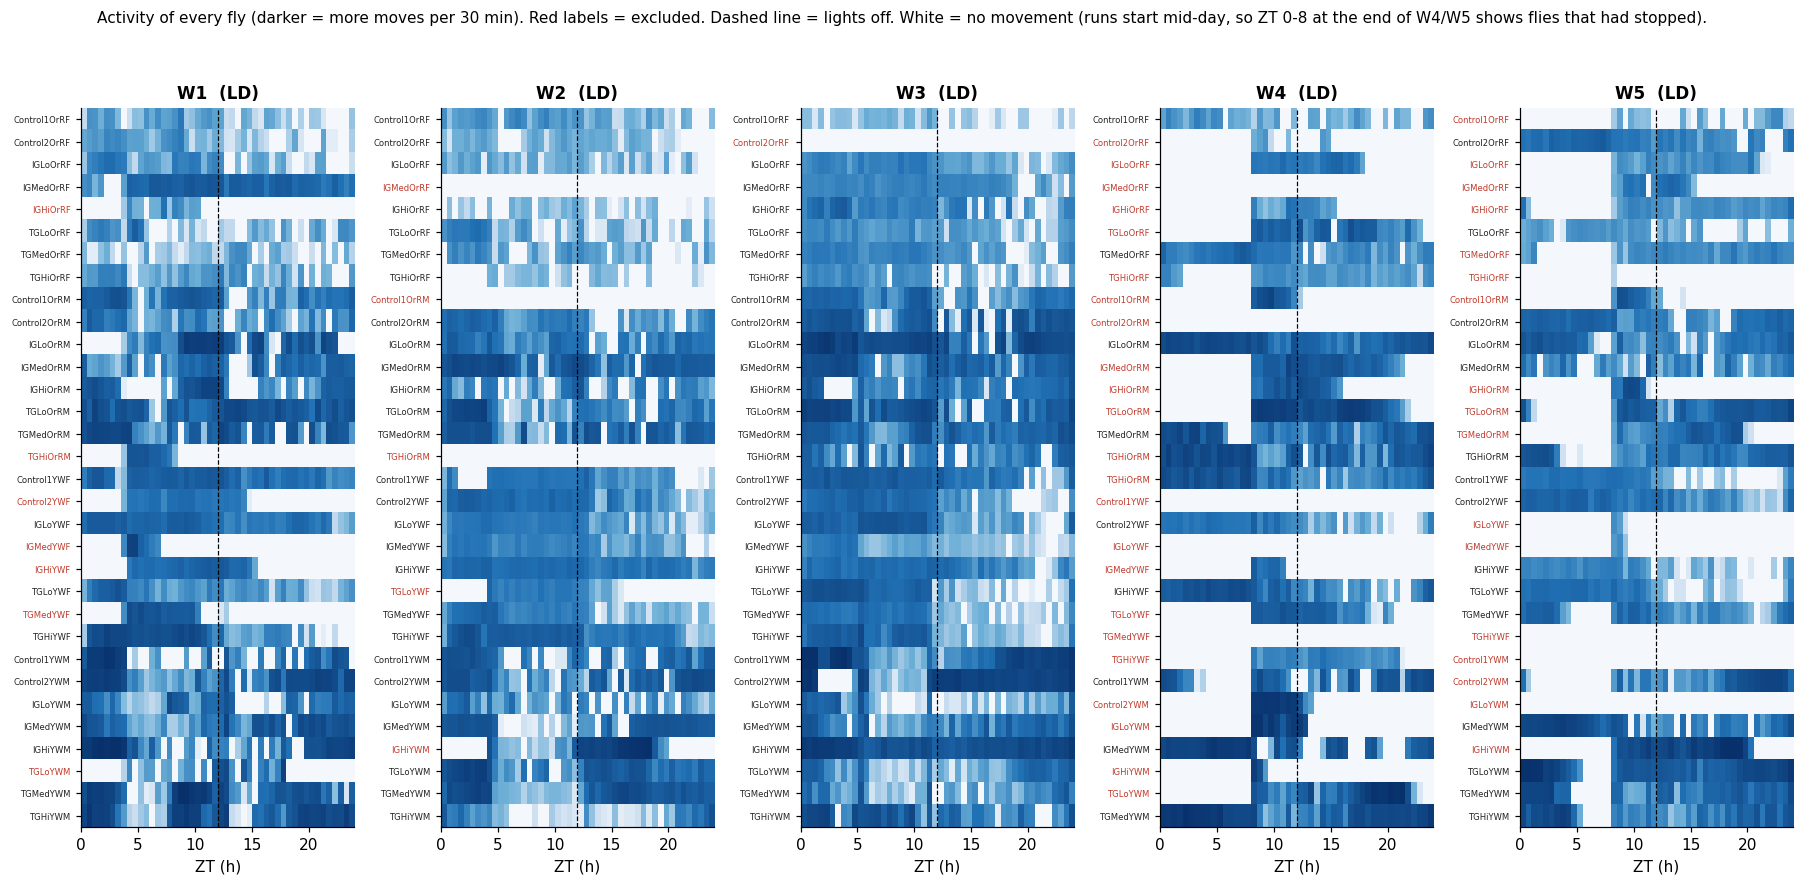

In [25]:
# Figure 1 - every fly, every run (activity heat-map, ZT on the x axis)
cmap = LinearSegmentedColormap.from_list("seq", ["#f4f8fc", "#c6dbef", "#6baed6", "#2171b5", "#08306b"])
fig, axes = plt.subplots(1, len(WINDOWS), figsize=(3.3 * len(WINDOWS), 8), sharey=False)
for ax, wname in zip(axes, WINDOWS):
    d = fl[fl["window"] == wname].copy()
    d["o"] = d["group"].map({g: i for i, g in enumerate(GROUP_ORDER)})
    d = d.sort_values(["strain", "sex", "o"])
    M = np.vstack([prof[f][0] for f in d["fid"]])
    ax.imshow(np.log1p(M), aspect="auto", cmap=cmap, extent=[0, 24, len(d), 0], interpolation="nearest")
    ax.axvline(DAY_HOURS, color="k", lw=0.8, ls="--")
    ax.set_yticks(np.arange(len(d)) + 0.5)
    ax.set_yticklabels(d["label"], fontsize=5.5)
    for t, ex in zip(ax.get_yticklabels(), d["excluded"]):
        t.set_color("#c0392b" if ex else "#222222")
    ax.set_xlabel("ZT (h)"); ax.set_title(f"{wname}  ({wobj[wname]['regime']})")
fig.suptitle("Activity of every fly (darker = more moves per 30 min). Red labels = excluded. Dashed line = lights off. "
             "White = no movement (runs start mid-day, so ZT 0-8 at the end of W4/W5 shows flies that had stopped).", y=1.0, fontsize=10)
fig.tight_layout(rect=[0, 0, 1, 0.97]); save(fig, "01_overview_heatmaps"); plt.show()

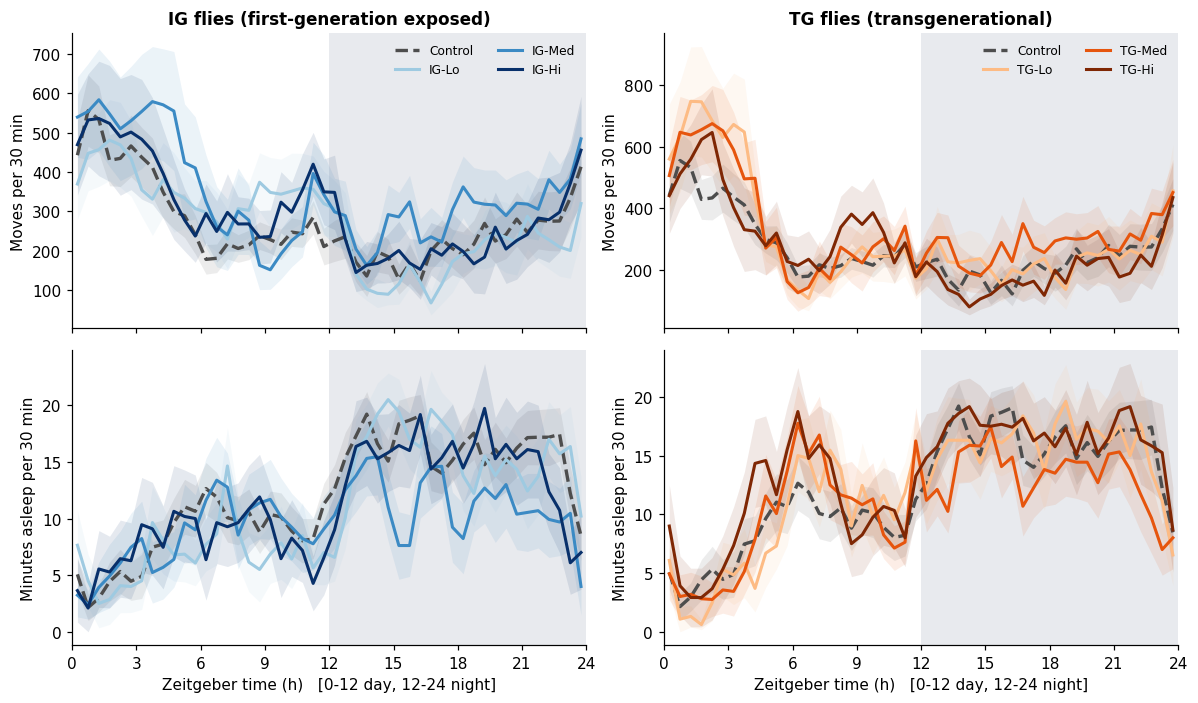

In [26]:
# Figure 2 - 24 h activity and sleep profiles, IG and TG against control
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True)
for j, tr in enumerate(["IG", "TG"]):
    groups = ["Control"] + [f"{tr}-{d}" for d in ("Lo", "Med", "Hi")]
    for i, (which, lab) in enumerate([(0, "Moves per 30 min"), (1, "Minutes asleep per 30 min")]):
        ax = axes[i, j]; shade_night(ax)
        for g, (m, s) in group_profile(ok, which, groups).items():
            ax.plot(XT, m, color=PCOL[g], lw=2 if g != "Control" else 2.2, ls="--" if g == "Control" else "-", label=g)
            ax.fill_between(XT, m - s, m + s, color=PCOL[g], alpha=0.10, lw=0)
        ax.set_ylabel(lab); ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 3))
        if i == 0: ax.set_title(f"{tr} flies" + (" (first-generation exposed)" if tr == "IG" else " (transgenerational)")); ax.legend(frameon=False, ncol=2, fontsize=8)
        if i == 1: ax.set_xlabel("Zeitgeber time (h)   [0-12 day, 12-24 night]")
fig.tight_layout(); save(fig, "02_profiles_activity_sleep"); plt.show()

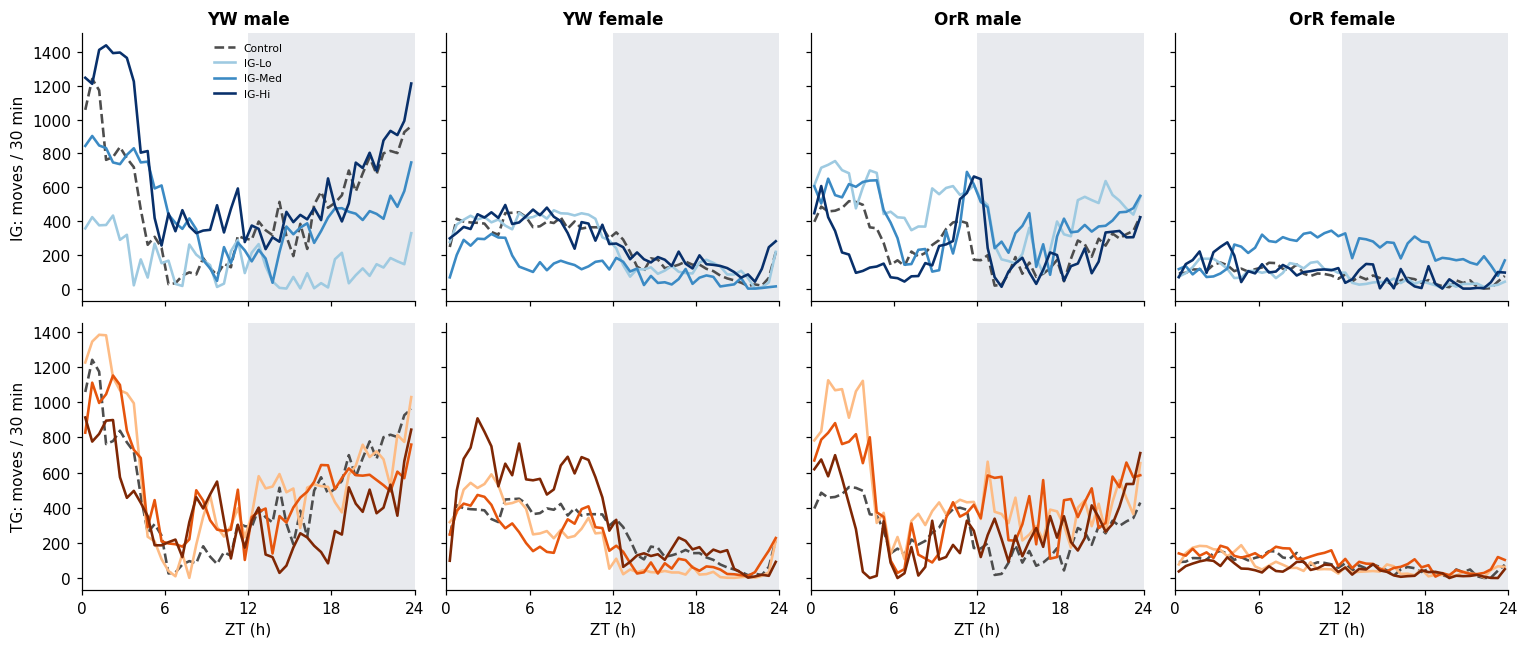

In [27]:
# Figure 3 - activity profile split by strain and sex
fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharex=True, sharey="row")
for r, tr in enumerate(["IG", "TG"]):
    for c, (strain, sex) in enumerate(STRATA):
        ax = axes[r, c]; shade_night(ax)
        sub = ok[(ok["strain"] == strain) & (ok["sex"] == sex)]
        for g, (m, s) in group_profile(sub, 0, ["Control"] + [f"{tr}-{d}" for d in ("Lo", "Med", "Hi")]).items():
            ax.plot(XT, m, color=PCOL[g], lw=1.7, ls="--" if g == "Control" else "-", label=g)
        ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 6))
        if r == 0: ax.set_title(f"{strain} {'male' if sex == 'M' else 'female'}")
        if c == 0: ax.set_ylabel(f"{tr}: moves / 30 min")
        if r == 1: ax.set_xlabel("ZT (h)")
        if r == 0 and c == 0: ax.legend(frameon=False, fontsize=7)
fig.tight_layout(); save(fig, "03_profiles_by_strain_sex"); plt.show()

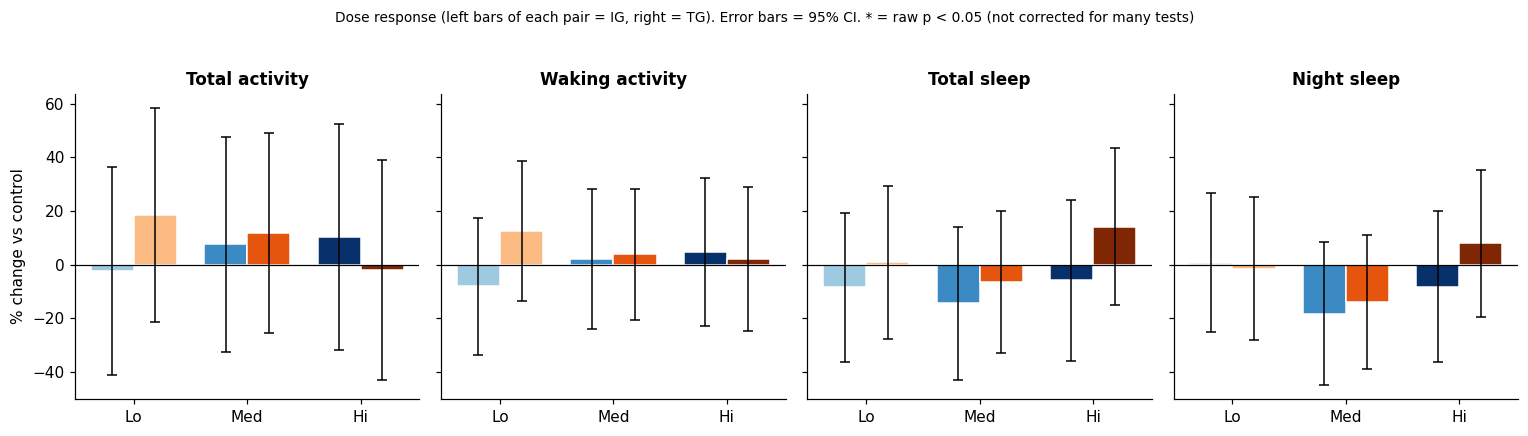

In [28]:
# Figure 4 - how much does each group differ from control? (pooled model, % change with 95% CI)
mets = [("total_act", "Total activity"), ("waking_act", "Waking activity"), ("sleep_min", "Total sleep"), ("sleep_night", "Night sleep")]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8), sharey=True)
x = np.arange(3); w = 0.38
for ax, (mk, ttl) in zip(axes, mets):
    o = ols[ols["metric"] == mk].set_index("group")
    cm = ok[ok["group"].isin(CONTROL_GROUPS)][mk].mean()
    for k, tr in enumerate(["IG", "TG"]):
        gs = [f"{tr}-{d}" for d in ("Lo", "Med", "Hi")]
        v = o.loc[gs, "coef"] / cm * 100; e = 1.96 * o.loc[gs, "se"] / cm * 100
        ax.bar(x + (k - 0.5) * w, v, w, yerr=e, color=[GROUP_COLORS[g] for g in gs], capsize=3, edgecolor="white", error_kw=dict(lw=1))
        for xi, g in zip(x + (k - 0.5) * w, gs):
            p = o.loc[g, "p_raw"]
            if p < 0.05: ax.text(xi, (o.loc[g, "coef"] + 1.96 * o.loc[g, "se"]) / cm * 100 + 3, "*", ha="center", fontsize=14)
    ax.axhline(0, color="k", lw=0.8); ax.set_xticks(x); ax.set_xticklabels(["Lo", "Med", "Hi"]); ax.set_title(ttl)
axes[0].set_ylabel("% change vs control")
fig.suptitle("Dose response (left bars of each pair = IG, right = TG). Error bars = 95% CI. * = raw p < 0.05 (not corrected for many tests)", y=1.03, fontsize=9)
fig.tight_layout(); save(fig, "04_effects_vs_control"); plt.show()

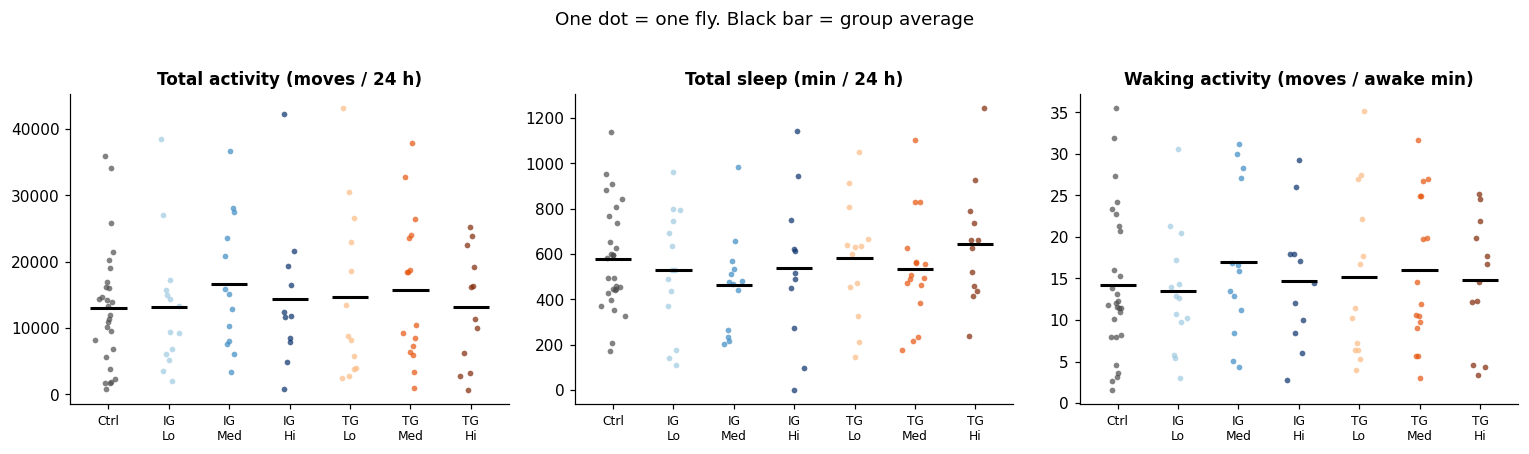

In [29]:
# Figure 5 - every fly as a dot (raw values by group)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
rng = np.random.default_rng(1)
for ax, mk in zip(axes, ["total_act", "sleep_min", "waking_act"]):
    for i, g in enumerate(["Control"] + TREAT_GROUPS):
        v = ok[ok["grp"] == g][mk].dropna()
        ax.scatter(i + rng.normal(0, 0.08, len(v)), v, s=14, color=PCOL[g], alpha=0.7, lw=0)
        ax.hlines(v.mean(), i - 0.3, i + 0.3, color="k", lw=2)
    ax.set_xticks(range(7)); ax.set_xticklabels(["Ctrl"] + [g.replace("-", "\n") for g in TREAT_GROUPS], fontsize=8)
    ax.set_title(METRICS[mk])
fig.suptitle("One dot = one fly. Black bar = group average", y=1.02)
fig.tight_layout(); save(fig, "05_per_fly_values"); plt.show()

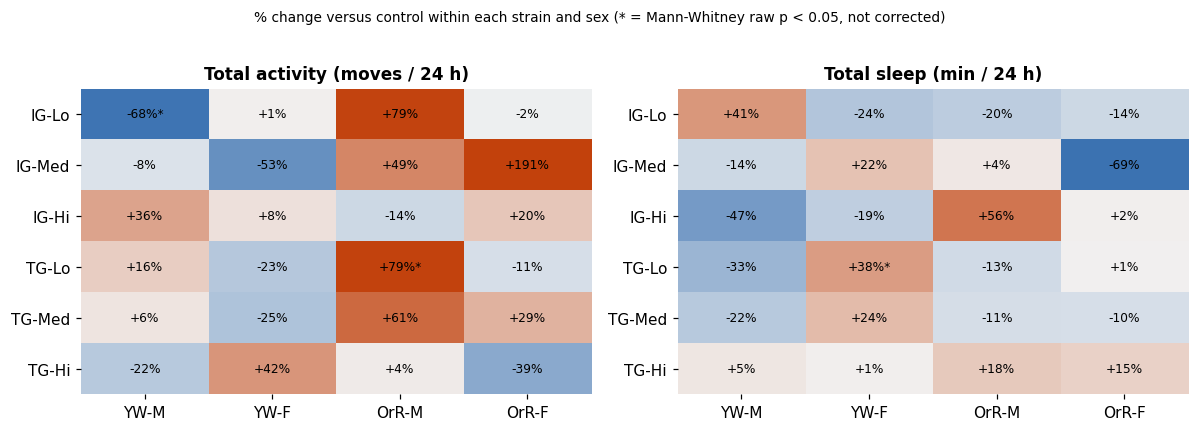

In [30]:
# Figure 6 - % change by strain and sex (Mann-Whitney stars)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
div = LinearSegmentedColormap.from_list("div", ["#1f5fa8", "#f2f2f2", "#c2410c"])
for ax, mk in zip(axes, ["total_act", "sleep_min"]):
    s = strat_only[strat_only["metric"] == mk]
    pv = s.pivot(index="group", columns="stratum", values="pct_change").reindex(TREAT_GROUPS)[[f"{a}-{b}" for a, b in STRATA]]
    pp = s.pivot(index="group", columns="stratum", values="p_raw").reindex(TREAT_GROUPS)[pv.columns]
    im = ax.imshow(pv.values, cmap=div, vmin=-80, vmax=80, aspect="auto")
    ax.set_xticks(range(4)); ax.set_xticklabels(pv.columns); ax.set_yticks(range(6)); ax.set_yticklabels(pv.index)
    for i in range(6):
        for j in range(4):
            if not np.isnan(pv.values[i, j]):
                ax.text(j, i, f"{pv.values[i, j]:+.0f}%" + ("*" if pp.values[i, j] < 0.05 else ""), ha="center", va="center", fontsize=8)
    ax.set_title(METRICS[mk]); ax.spines[:].set_visible(False)
fig.suptitle("% change versus control within each strain and sex (* = Mann-Whitney raw p < 0.05, not corrected)", y=1.02, fontsize=9)
fig.tight_layout(); save(fig, "06_effect_heatmap_by_stratum"); plt.show()

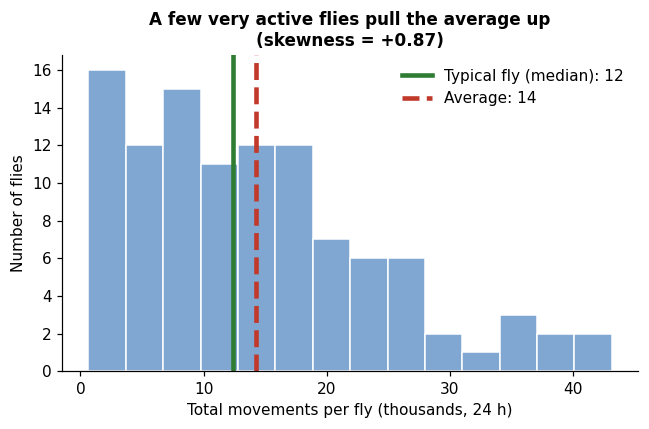

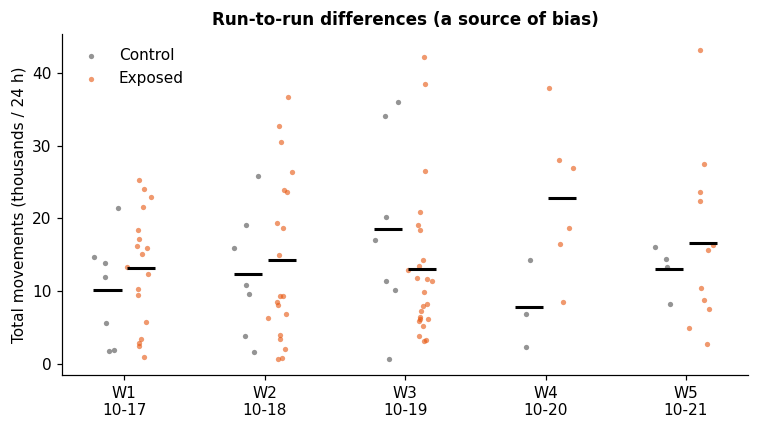

In [31]:
# Figure 7 - skewness (why we use rank tests)
fig, ax = plt.subplots(figsize=(6, 4))
v = ok["total_act"] / 1000
ax.hist(v, bins=14, color="#7FA7D1", edgecolor="white")
ax.axvline(v.median(), color="#2E7D32", lw=3, label=f"Typical fly (median): {v.median():.0f}")
ax.axvline(v.mean(), color="#C0392B", lw=3, ls="--", label=f"Average: {v.mean():.0f}")
ax.set_xlabel("Total movements per fly (thousands, 24 h)"); ax.set_ylabel("Number of flies")
ax.set_title(f"A few very active flies pull the average up\n(skewness = {skew(ok['total_act']):+.2f})")
ax.legend(frameon=False); fig.tight_layout(); save(fig, "07_skewness"); plt.show()

# Figure 8 - bias check: does the run (batch) change activity regardless of treatment?
fig, ax = plt.subplots(figsize=(7, 4))
for i, wname in enumerate(WINDOWS):
    d = ok[ok["window"] == wname]
    for kind, col, off in [("Control", "#4d4d4d", -0.12), ("Exposed", "#e6550d", 0.12)]:
        vals = d[(d["treatment"] == "Control") == (kind == "Control")]["total_act"] / 1000
        ax.scatter(i + off + np.random.default_rng(2).normal(0, 0.04, len(vals)), vals, s=12, color=col, alpha=0.6, lw=0, label=kind if i == 0 else None)
        ax.hlines(vals.mean(), i + off - 0.1, i + off + 0.1, color="k", lw=2)
ax.set_xticks(range(len(WINDOWS))); ax.set_xticklabels([f"{k}\n{v['start'][5:10]}" for k, v in WINDOWS.items()])
ax.set_ylabel("Total movements (thousands / 24 h)"); ax.set_title("Run-to-run differences (a source of bias)"); ax.legend(frameon=False)
fig.tight_layout(); save(fig, "08_run_to_run_check"); plt.show()

In [32]:
lines = []
n_all, n_ok = len(fl), len(ok)
lines.append(f"Runs analysed: {', '.join(WINDOWS)} (Oct 17-22, 2026), {n_all} fly-runs, {n_ok} kept, {n_all - n_ok} excluded.")
for reason in ["duplicate label", "dead?", "low coverage", "unreadable"]:
    k = fl["flags"].str.contains(reason, regex=False).sum()
    if k: lines.append(f"  excluded for '{reason}': {k}")
lines.append("Usable flies per group: " + ", ".join(f"{g} {n}" for g, n in ok.groupby("grp").size().reindex(['Control'] + TREAT_GROUPS).items()))
lines.append("")
lines.append("Pooled model, % change versus control (raw p / Holm p):")
for mk, ttl in [("total_act", "total activity"), ("waking_act", "waking activity"), ("sleep_min", "total sleep"), ("sleep_night", "night sleep")]:
    o = ols[ols["metric"] == mk].sort_values("p_raw")
    lines.append(f"  {ttl}: " + "; ".join(f"{r.group} {r.pct_vs_ctrl:+.0f}% (p={r.p_raw:.3f}, Holm {r.p_holm:.2f})" for r in o.itertuples()))
lines.append("")
lines.append(f"Mann-Whitney tests within strain x sex: {n_tests}; raw p<0.05: {(strat_only['p_raw'] < 0.05).sum()} (about {0.05 * n_tests:.0f} expected by chance); BH q<0.05: {(strat_only['p_fdr'] < 0.05).sum()}.")
nmed = ok.groupby("grp").size().median()
mde = 2.8 * np.sqrt(1 / nmed + 1 / ok[ok['grp'] == 'Control'].shape[0])
lines.append(f"Power: with about {nmed:.0f} flies per treatment group, only effects of roughly {mde:.1f} standard deviations are reliably detectable.")
lines.append(f"Skewness of total activity: {skew(ok['total_act']):+.2f} (right-skewed) -> rank tests used.")
lines.append("")
lines.append(f"Flies that stopped moving mid-run (excluded in the main analysis): {int(fl['stopped'].sum())} of {len(fl)}. Rate differs by group? chi-square p = {chi_group:.2f}; by run? p = {chi_run:.4f}.")
lines.append("Sensitivity analysis keeping those flies is saved in stats_sensitivity_keep_stopped_flies.csv.")
txt = "\n".join(lines)
(OUTDIR / "key_findings.txt").write_text(txt)
print(txt)

Runs analysed: W1, W2, W3, W4, W5 (Oct 17-22, 2026), 160 fly-runs, 107 kept, 53 excluded.
  excluded for 'duplicate label': 2
  excluded for 'dead?': 51
Usable flies per group: Control 28, IG-Lo 14, IG-Med 13, IG-Hi 11, TG-Lo 13, TG-Med 16, TG-Hi 12

Pooled model, % change versus control (raw p / Holm p):
  total activity: TG-Lo +19% (p=0.365, Holm 1.00); TG-Med +12% (p=0.535, Holm 1.00); IG-Hi +10% (p=0.629, Holm 1.00); IG-Med +8% (p=0.712, Holm 1.00); IG-Lo -2% (p=0.905, Holm 1.00); TG-Hi -2% (p=0.926, Holm 1.00)
  waking activity: TG-Lo +12% (p=0.351, Holm 1.00); IG-Lo -8% (p=0.531, Holm 1.00); IG-Hi +5% (p=0.735, Holm 1.00); TG-Med +4% (p=0.760, Holm 1.00); TG-Hi +2% (p=0.877, Holm 1.00); IG-Med +2% (p=0.886, Holm 1.00)
  total sleep: IG-Med -14% (p=0.324, Holm 1.00); TG-Hi +14% (p=0.349, Holm 1.00); IG-Lo -8% (p=0.551, Holm 1.00); TG-Med -7% (p=0.628, Holm 1.00); IG-Hi -6% (p=0.706, Holm 1.00); TG-Lo +1% (p=0.949, Holm 1.00)
  night sleep: IG-Med -18% (p=0.184, Holm 1.00); TG-Med 